# 03 · Evaluación, análisis de errores y generalización externa
1. Prueba interna en **BRACOL test** (253 hojas nunca vistas) para los 4 modelos.
2. Análisis de errores del mejor modelo (elegido por F1 de **validación**).
3. **Generalización externa en RoCoLe** (otra variedad, otro país, otra cámara, hoja en campo), en tres versiones: `raw`, `crop`, `mask`.
4. Comportamiento ante una clase nunca vista (**arañita roja**, *out-of-distribution*).
5. **Grad-CAM**: ¿dónde mira el modelo?

In [1]:
# ===== Configuración del entorno (Colab o local) =====
import os, sys, json, shutil, zipfile, time
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/drive/MyDrive").exists():          # ya montado si se ejecuta desde el lanzador
        from google.colab import drive
        drive.mount("/content/drive")
    DRIVE = Path("/content/drive/MyDrive/ProyectoCafe")     # aquí está src/ y se guardan los resultados
    ROOT = Path("/content/proyecto")
    shutil.copytree(DRIVE / "src", ROOT / "src", dirs_exist_ok=True)
    (ROOT / "src" / "__init__.py").touch()
    os.environ["PROYECTO_ROOT"], os.environ["PROYECTO_OUT"] = str(ROOT), str(DRIVE)
    !pip -q install timm
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    os.environ.setdefault("PROYECTO_ROOT", str(ROOT)); os.environ.setdefault("PROYECTO_OUT", str(ROOT))
    DRIVE = Path(os.environ["PROYECTO_OUT"])
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from src import config as C
C.FIG.mkdir(parents=True, exist_ok=True); C.RUNS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False})
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE, "| ROOT:", ROOT, "| salidas:", C.OUT)

Dispositivo: cpu | ROOT: C:\Users\LENOVO\Documents\UNIVERSIDAD\Deeplearning\Proyecto final | salidas: C:\Users\LENOVO\Documents\UNIVERSIDAD\Deeplearning\Proyecto final


In [2]:
# ===== Datos: descarga + versiones RoCoLe + caché uint8 (letterbox 256) =====
from src.data import (download_bracol, download_rocole, build_rocole_versions, build_tables,
                      get_caches, load_tables, split_fingerprint)
DRIVE_CACHE = DRIVE / "cache"
names = ["bracol", "rocole_raw", "rocole_crop", "rocole_mask"]
tables = ["bracol_leaf.csv", "rocole.csv", "meta.json"]
if IN_COLAB and DRIVE_CACHE.exists():                      # reutiliza caché y tablas de una sesión anterior
    C.CACHE.mkdir(parents=True, exist_ok=True); C.PROC.mkdir(parents=True, exist_ok=True)
    for f in list(DRIVE_CACHE.glob("*.pt")) + [DRIVE_CACHE / t for t in tables if (DRIVE_CACHE / t).exists()]:
        dst = (C.CACHE if f.suffix == ".pt" else C.PROC) / f.name
        if not dst.exists():
            shutil.copy(f, dst)
if not all((C.CACHE / f"{n}.pt").exists() for n in names) or not (C.PROC / "bracol_leaf.csv").exists():
    t = time.time()
    download_bracol(); download_rocole(); build_tables(); build_rocole_versions()
    print(f"Descarga y preprocesamiento: {time.time() - t:.0f} s")
fp = split_fingerprint()
print("Huella de la partición:", fp)
assert fp == "bd076d1914a2", "La partición no coincide con la del notebook 01"
caches = get_caches()
GUARDAR_CACHE = IN_COLAB and os.environ.get("CACHE_EN_DRIVE", "1") == "1"   # ~1.2 GB en Drive (opcional)
if GUARDAR_CACHE and not all((DRIVE_CACHE / f"{n}.pt").exists() for n in names):
    DRIVE_CACHE.mkdir(parents=True, exist_ok=True)
    for n in names:
        shutil.copy(C.CACHE / f"{n}.pt", DRIVE_CACHE / f"{n}.pt")
    for t in tables:
        shutil.copy(C.PROC / t, DRIVE_CACHE / t)
bra, roc = load_tables()
print({k: tuple(v.shape) for k, v in caches.items()})
print(bra.split.value_counts().to_dict())

Huella de la partición: bd076d1914a2


{'bracol': (1685, 3, 256, 256), 'rocole_raw': (1560, 3, 256, 256), 'rocole_crop': (1560, 3, 256, 256), 'rocole_mask': (1560, 3, 256, 256)}
{'train': 1179, 'test': 253, 'val': 253}


In [3]:
from src.evaluate import load_trained, predict_proba, multiclass_metrics, healthy_vs_diseased, latency_ms, GradCAM
from src.train import RUNS_CFG
NOMBRES = {"cnn_base": "CNN base", "effnet_b0": "EfficientNet-B0", "vit_tiny": "ViT-Tiny", "effnet_b0_sinaug": "EffNet-B0 sin aum."}
test_idx = bra.index[bra.split == "test"].to_numpy(); y_test = bra.label.values[test_idx]
ind = roc.index[roc.label >= 0].to_numpy(); y_roc = roc.label.values[ind]          # sana (0) / roya (2)
ood = roc.index[roc.rocole_class == "red_spider_mite"].to_numpy()

models, P, summ = {}, {}, {}
for run in RUNS_CFG:
    m, arch, s = load_trained(run, DEVICE); models[run] = (m, arch); summ[run] = s
    P[(run, "test")] = predict_proba(m, caches["bracol"][test_idx])
    for v in C.ROCOLE_VERSIONS:
        P[(run, v)] = predict_proba(m, caches[f"rocole_{v}"])
np.savez_compressed(C.RUNS / "probabilidades.npz", **{f"{r}__{k}": p for (r, k), p in P.items()})
BEST = max(["cnn_base", "effnet_b0", "vit_tiny"], key=lambda r: summ[r]["best_val_f1"])
print("Mejor modelo según F1 de VALIDACIÓN:", BEST, {r: round(summ[r]["best_val_f1"], 4) for r in summ})

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_26788\1316933388.py:11: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  P[(run, "test")] = predict_proba(m, caches["bracol"][test_idx])


Mejor modelo según F1 de VALIDACIÓN: vit_tiny {'cnn_base': 0.8765, 'effnet_b0': 0.915, 'vit_tiny': 0.9349, 'effnet_b0_sinaug': 0.9129}


## 1. Resultados en BRACOL test

,modelo,accuracy,precision_macro,recall_macro,f1_macro,params_M,entrenamiento_min,ms_img_gpu,ms_img_cpu
0,CNN base,0.8419,0.8095,0.8181,0.8083,1.1745,105.2755,NaN,67.2872
1,EfficientNet-B0,0.8814,0.8606,0.8851,0.8635,4.0140,88.5886,NaN,53.1845
2,ViT-Tiny,0.8735,0.8457,0.8447,0.8426,5.5254,53.2669,NaN,44.6759
3,EffNet-B0 sin aum.,0.8814,0.8495,0.8541,0.8513,4.0140,76.3213,NaN,41.0622


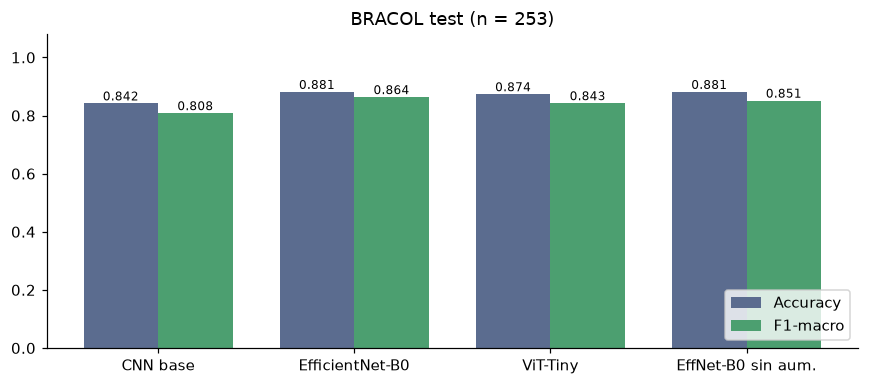

In [4]:
rows, M = [], {}
for run in RUNS_CFG:
    M[run] = multiclass_metrics(y_test, P[(run, "test")])
    m, _ = models[run]
    lat_gpu = latency_ms(m) if DEVICE.type == "cuda" else float("nan")
    lat_cpu = latency_ms(m.cpu(), torch.device("cpu"), n=20); m.to(DEVICE)
    rows.append({"modelo": NOMBRES[run], "accuracy": M[run]["accuracy"], "precision_macro": M[run]["precision_macro"],
                 "recall_macro": M[run]["recall_macro"], "f1_macro": M[run]["f1_macro"],
                 "params_M": summ[run]["params"]["total"] / 1e6, "entrenamiento_min": summ[run]["train_time_s"] / 60,
                 "ms_img_gpu": lat_gpu, "ms_img_cpu": lat_cpu})
test_df = pd.DataFrame(rows).round(4); display(test_df)
test_df.to_csv(C.RUNS / "resultados_test.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(test_df)); w = 0.38
ax.bar(x - w/2, test_df.accuracy, w, label="Accuracy", color="#5B6C8F"); ax.bar(x + w/2, test_df.f1_macro, w, label="F1-macro", color="#4C9F70")
for i, (a, f) in enumerate(zip(test_df.accuracy, test_df.f1_macro)):
    ax.text(i - w/2, a + .01, f"{a:.3f}", ha="center", fontsize=8); ax.text(i + w/2, f + .01, f"{f:.3f}", ha="center", fontsize=8)
ax.set_xticks(x, test_df.modelo); ax.set_ylim(0, 1.08); ax.set_title("BRACOL test (n = %d)" % len(y_test)); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(C.FIG / "03_test_comparacion.png"); plt.show()

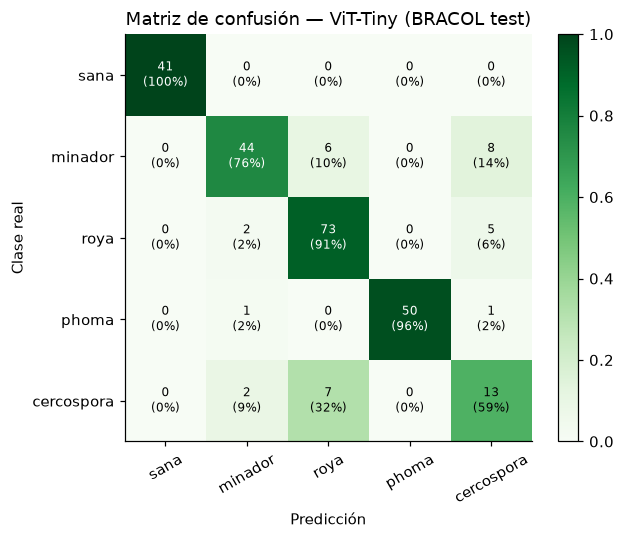

,precision,recall,f1-score,support
sana,1.000,1.000,1.000,41.000
minador,0.898,0.759,0.822,58.000
roya,0.849,0.912,0.880,80.000
phoma,1.000,0.962,0.980,52.000
cercospora,0.481,0.591,0.531,22.000
accuracy,0.874,0.874,0.874,0.874
macro avg,0.846,0.845,0.843,253.000
weighted avg,0.884,0.874,0.876,253.000


In [5]:
cm = np.array(M[BEST]["confusion"]); cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cmn, cmap="Greens", vmin=0, vmax=1)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{cm[i, j]}\n({cmn[i, j]:.0%})", ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > .6 else "black")
ax.set_xticks(range(5), C.CLASSES, rotation=30); ax.set_yticks(range(5), C.CLASSES)
ax.set_xlabel("Predicción"); ax.set_ylabel("Clase real"); ax.set_title(f"Matriz de confusión — {NOMBRES[BEST]} (BRACOL test)")
plt.colorbar(im, fraction=.046); plt.tight_layout(); plt.savefig(C.FIG / "03_matriz_confusion_test.png"); plt.show()
pc = pd.DataFrame(M[BEST]["per_class"]).T.round(3); display(pc)
pc.to_csv(C.RUNS / "reporte_por_clase_test.csv")

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_26788\1747291463.py:3: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  tb["n_estreses"] = tb[["miner", "rust", "phoma", "cercospora"]].sum(1)


,accuracy,n
tipo,,
sana,1.000,41
un estrés,0.922,153
varios estreses,0.661,59


,accuracy,n
severity,,
0,1.000,41
1,0.793,140
2,0.958,48
3,0.944,18
4,1.000,6


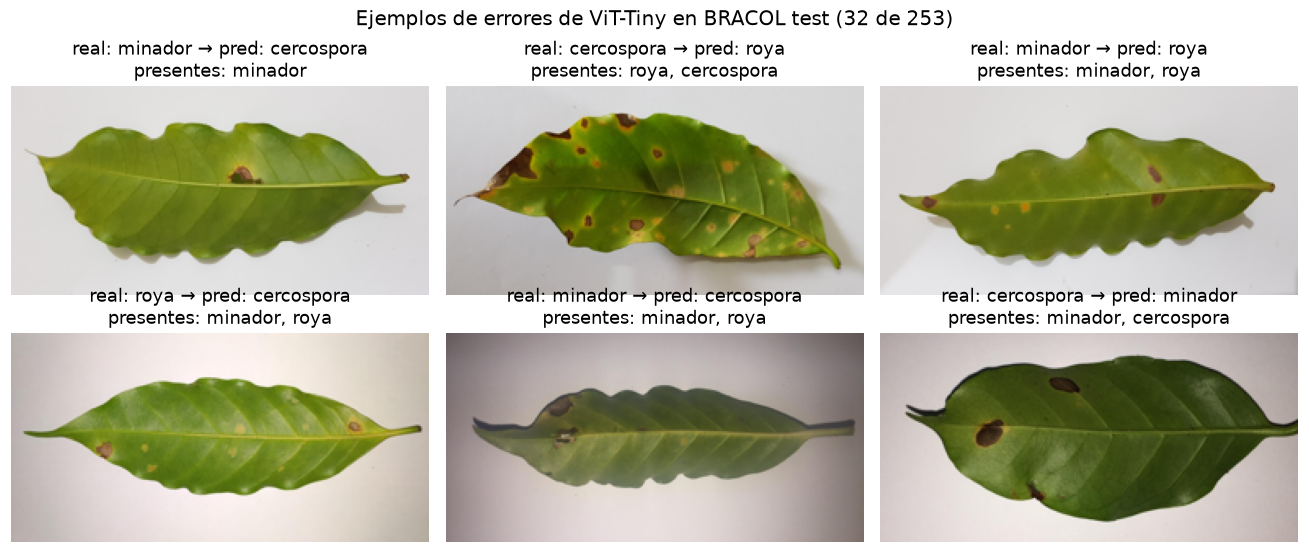

In [6]:
# ¿Los errores se concentran en hojas con varios estreses simultáneos?
tb = bra.loc[test_idx].copy(); tb["pred"] = P[(BEST, "test")].argmax(1); tb["ok"] = tb.pred == tb.label
tb["n_estreses"] = tb[["miner", "rust", "phoma", "cercospora"]].sum(1)
tb["tipo"] = np.where(tb.n_estreses > 1, "varios estreses", np.where(tb.n_estreses == 1, "un estrés", "sana"))
multi = tb.groupby("tipo").ok.agg(["mean", "count"]).rename(columns={"mean": "accuracy", "count": "n"}); display(multi.round(3))
# ¿y con la severidad?
display(tb.groupby("severity").ok.agg(["mean", "count"]).rename(columns={"mean": "accuracy", "count": "n"}).round(3))

err = tb[~tb.ok]
k = min(6, len(err))
if k:
    fig, axes = plt.subplots(2, 3, figsize=(12, 5.2))
    for ax in axes.ravel(): ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), err.sample(k, random_state=0).iterrows()):
        x = caches["bracol"][r.name][:, 64:192, :]            # recorta el relleno del letterbox (hoja 2:1)
        ax.imshow(x.permute(1, 2, 0))
        otros = [n for n, c in zip(["minador", "roya", "phoma", "cercospora"], ["miner", "rust", "phoma", "cercospora"]) if r[c]]
        ax.set_title(f"real: {C.CLASSES[r.label]} → pred: {C.CLASSES[r.pred]}\npresentes: {', '.join(otros) or '—'}", fontsize=12)
    fig.suptitle(f"Ejemplos de errores de {NOMBRES[BEST]} en BRACOL test ({len(err)} de {len(tb)})", fontsize=13)
    plt.tight_layout(); plt.savefig(C.FIG / "03_errores_test.png"); plt.show()

## 2. Generalización externa — RoCoLe
RoCoLe solo contiene **sana** y **roya** dentro del espacio de etiquetas de BRACOL. Se reportan:
- **Accuracy estricta (5 clases):** acierto exacto; el modelo puede equivocarse prediciendo cualquiera de las 5 clases.
- **Tarea binaria sana vs. enferma:** puntaje = 1 − p(sana). Mide si el modelo detecta *que hay enfermedad*, aunque confunda cuál.
  Se calcula también en BRACOL test para comparar en igualdad de condiciones.

,modelo,dominio,acc_5clases,accuracy,f1_enferma,recall_enferma,recall_sana,auroc
0,CNN base,BRACOL test,0.8419,0.9723,0.9832,0.9670,1.0000,1.0000
1,CNN base,RoCoLe raw,0.2161,0.4896,0.6171,0.9518,0.1378,0.5727
2,CNN base,RoCoLe crop,0.2850,0.5097,0.6314,0.9718,0.1580,0.7022
3,CNN base,RoCoLe mask,0.7710,0.8658,0.8283,0.7492,0.9545,0.9171
4,EfficientNet-B0,BRACOL test,0.8814,1.0000,1.0000,1.0000,1.0000,1.0000
5,EfficientNet-B0,RoCoLe raw,0.5513,0.5707,0.5372,0.5764,0.5664,0.5905
6,EfficientNet-B0,RoCoLe crop,0.5061,0.5312,0.6011,0.8173,0.3135,0.6141
7,EfficientNet-B0,RoCoLe mask,0.6963,0.7846,0.7826,0.8970,0.6991,0.8959
8,ViT-Tiny,BRACOL test,0.8735,1.0000,1.0000,1.0000,1.0000,1.0000
9,ViT-Tiny,RoCoLe raw,0.3130,0.4537,0.6115,0.9950,0.0417,0.7531


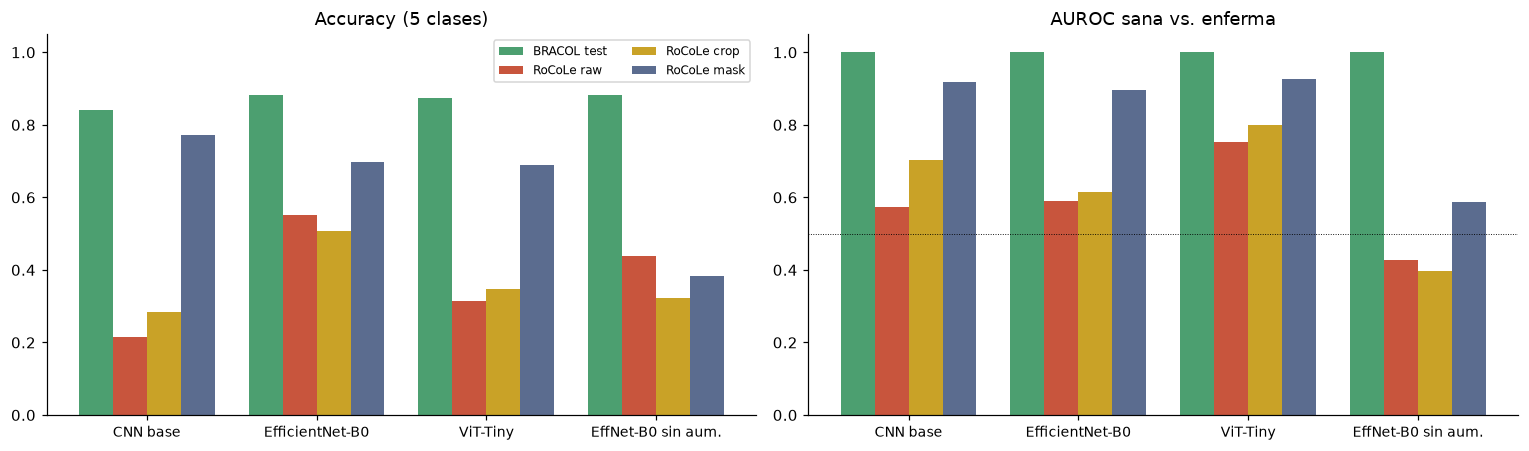

In [7]:
rows = []
for run in RUNS_CFG:
    hb = healthy_vs_diseased(y_test, P[(run, "test")])
    rows.append({"modelo": NOMBRES[run], "dominio": "BRACOL test", "acc_5clases": M[run]["accuracy"], **hb})
    for v in C.ROCOLE_VERSIONS:
        p = P[(run, v)][ind]
        rows.append({"modelo": NOMBRES[run], "dominio": f"RoCoLe {v}", "acc_5clases": float((p.argmax(1) == y_roc).mean()),
                     **healthy_vs_diseased(y_roc, p)})
ext_df = pd.DataFrame(rows).round(4); display(ext_df)
ext_df.to_csv(C.RUNS / "resultados_externos.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
doms = ["BRACOL test", "RoCoLe raw", "RoCoLe crop", "RoCoLe mask"]; cols = ["#4C9F70", "#C8553D", "#C9A227", "#5B6C8F"]
for ax, met, ttl in zip(axes, ["acc_5clases", "auroc"], ["Accuracy (5 clases)", "AUROC sana vs. enferma"]):
    mods = [NOMBRES[r] for r in RUNS_CFG]; x = np.arange(len(mods)); w = 0.2
    for k, (d, c) in enumerate(zip(doms, cols)):
        vals = [ext_df[(ext_df.modelo == m) & (ext_df.dominio == d)][met].item() for m in mods]
        ax.bar(x + (k - 1.5) * w, vals, w, label=d, color=c)
    ax.set_xticks(x, mods, fontsize=9); ax.set_ylim(0, 1.05); ax.set_title(ttl)
    ax.axhline(0.5 if met == "auroc" else 0, color="k", lw=.6, ls=":")
axes[0].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig(C.FIG / "03_generalizacion.png"); plt.show()

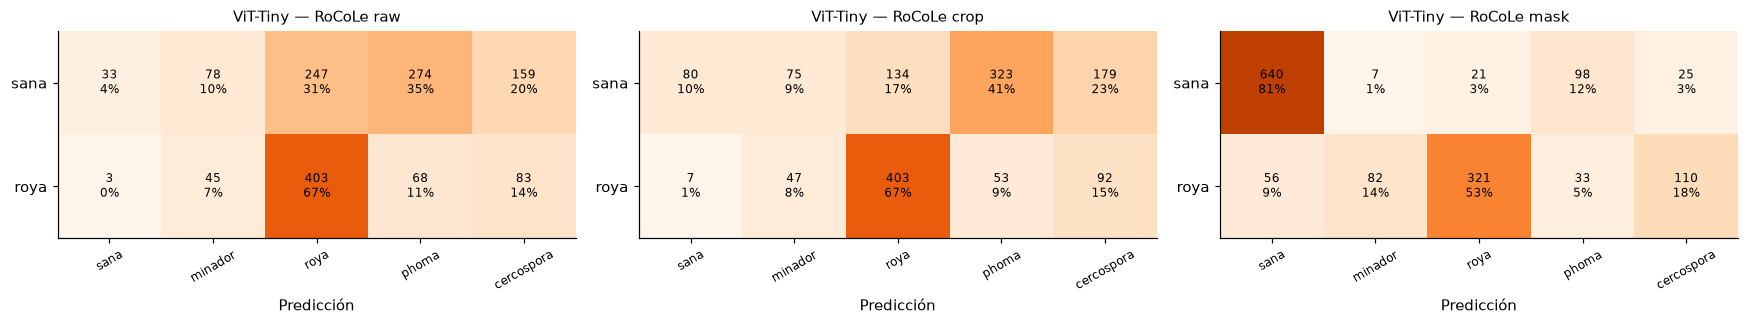

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.2))
for ax, v in zip(axes, C.ROCOLE_VERSIONS):
    pr = P[(BEST, v)][ind].argmax(1)
    cmx = np.array([[np.sum((y_roc == t) & (pr == j)) for j in range(5)] for t in (0, 2)])
    cmxn = cmx / cmx.sum(1, keepdims=True)
    ax.imshow(cmxn, cmap="Oranges", vmin=0, vmax=1)
    for i in range(2):
        for j in range(5):
            ax.text(j, i, f"{cmx[i, j]}\n{cmxn[i, j]:.0%}", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(5), C.CLASSES, rotation=30, fontsize=8); ax.set_yticks([0, 1], ["sana", "roya"])
    ax.set_title(f"{NOMBRES[BEST]} — RoCoLe {v}", fontsize=10); ax.set_xlabel("Predicción")
plt.tight_layout(); plt.savefig(C.FIG / "03_confusion_rocole.png"); plt.show()

,% predicho enfermo (raw),% predicho enfermo (crop),% predicho enfermo (mask)
rocole_class,,,
healthy,0.958,0.899,0.191
rust_level_1,0.991,0.980,0.840
rust_level_2,1.000,1.000,0.994
rust_level_3,1.000,1.000,1.000
rust_level_4,1.000,1.000,1.000


acierto_raw  acierto_crop  acierto_mask
lado  clase                                         
?     roya         1.000         0.000         0.000
envés roya         0.648         0.655         0.463
      sana         0.066         0.137         0.919
haz   roya         0.688         0.685         0.599
      sana         0.018         0.065         0.701

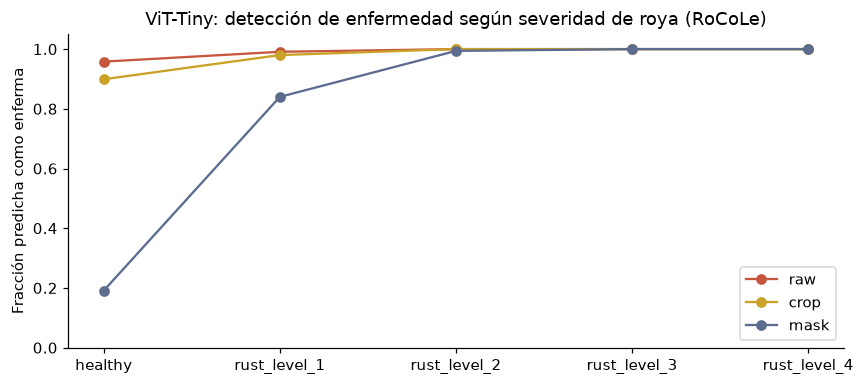

In [9]:
# Desglose por nivel de roya y por lado de la hoja (mejor modelo)
r_ind = roc.loc[ind].copy()
for v in C.ROCOLE_VERSIONS:
    pr = P[(BEST, v)][ind]
    r_ind[f"enferma_{v}"] = pr.argmax(1) != 0
    r_ind[f"acierto_{v}"] = pr.argmax(1) == y_roc
lvl = r_ind.groupby("rocole_class")[[f"enferma_{v}" for v in C.ROCOLE_VERSIONS]].mean().round(3)
lvl.columns = [f"% predicho enfermo ({v})" for v in C.ROCOLE_VERSIONS]; display(lvl)
lado = r_ind.groupby(["lado", "clase"])[[f"acierto_{v}" for v in C.ROCOLE_VERSIONS]].mean().round(3); display(lado)
lvl.to_csv(C.RUNS / "rocole_por_nivel.csv"); lado.to_csv(C.RUNS / "rocole_por_lado.csv")

fig, ax = plt.subplots(figsize=(8, 3.6))
order = ["healthy", "rust_level_1", "rust_level_2", "rust_level_3", "rust_level_4"]
for v, c in zip(C.ROCOLE_VERSIONS, ["#C8553D", "#C9A227", "#5B6C8F"]):
    ax.plot(order, lvl.loc[order, f"% predicho enfermo ({v})"], "-o", color=c, label=v)
ax.set_ylabel("Fracción predicha como enferma"); ax.set_ylim(0, 1.05); ax.legend()
ax.set_title(f"{NOMBRES[BEST]}: detección de enfermedad según severidad de roya (RoCoLe)")
plt.tight_layout(); plt.savefig(C.FIG / "03_rocole_severidad.png"); plt.show()

## 3. Clase nunca vista: arañita roja (*out-of-distribution*)

,versión,sana,minador,roya,phoma,cercospora,confianza media OOD,confianza media sana/roya,AUROC detección OOD (MSP)
0,raw,0.006,0.216,0.545,0.132,0.102,0.539,0.513,0.448
1,crop,0.012,0.317,0.365,0.120,0.186,0.549,0.521,0.456
2,mask,0.060,0.461,0.216,0.144,0.120,0.665,0.703,0.569


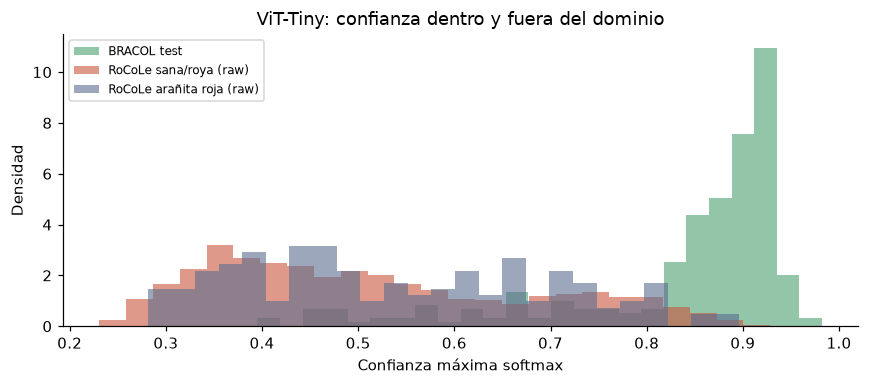

In [10]:
from sklearn.metrics import roc_auc_score
rows = []
for v in C.ROCOLE_VERSIONS:
    pr = P[(BEST, v)][ood]
    d = pd.Series(pr.argmax(1)).map(dict(enumerate(C.CLASSES))).value_counts(normalize=True).reindex(C.CLASSES).fillna(0)
    msp_in = P[(BEST, v)][ind].max(1); msp_ood = pr.max(1)
    auc = roc_auc_score(np.r_[np.zeros(len(msp_in)), np.ones(len(msp_ood))], -np.r_[msp_in, msp_ood])
    rows.append({"versión": v, **d.round(3).to_dict(), "confianza media OOD": msp_ood.mean(), "confianza media sana/roya": msp_in.mean(),
                 "AUROC detección OOD (MSP)": auc})
ood_df = pd.DataFrame(rows).round(3); display(ood_df); ood_df.to_csv(C.RUNS / "ood_aranita.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(P[(BEST, "test")].max(1), bins=25, alpha=.6, density=True, label="BRACOL test", color="#4C9F70")
ax.hist(P[(BEST, "raw")][ind].max(1), bins=25, alpha=.6, density=True, label="RoCoLe sana/roya (raw)", color="#C8553D")
ax.hist(P[(BEST, "raw")][ood].max(1), bins=25, alpha=.6, density=True, label="RoCoLe arañita roja (raw)", color="#5B6C8F")
ax.set_xlabel("Confianza máxima softmax"); ax.set_ylabel("Densidad"); ax.legend(fontsize=8)
ax.set_title(f"{NOMBRES[BEST]}: confianza dentro y fuera del dominio")
plt.tight_layout(); plt.savefig(C.FIG / "03_confianza_ood.png"); plt.show()

## 4. Grad-CAM — ¿en qué se fija el modelo?

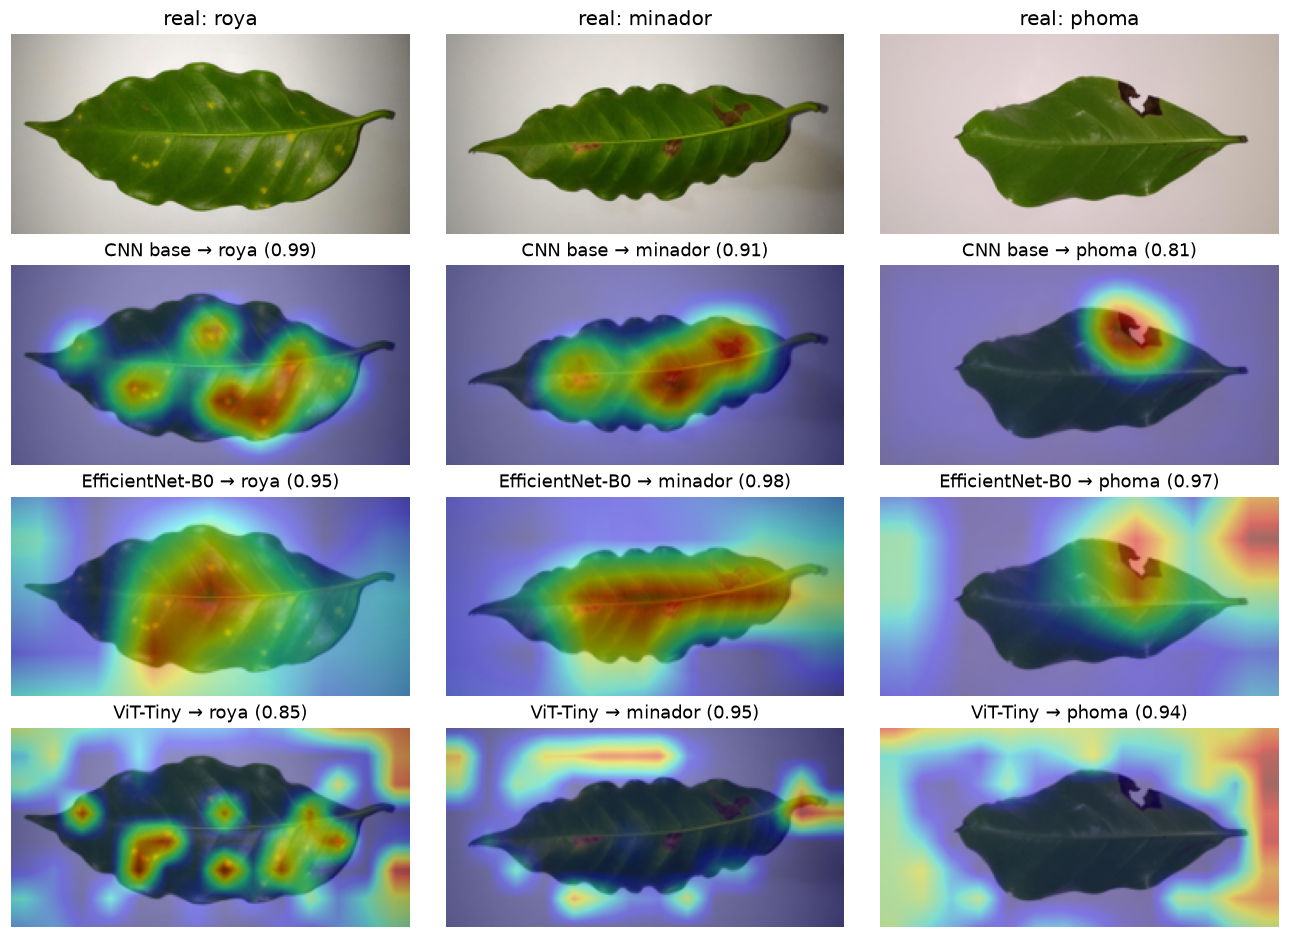

In [11]:
from src.data import get_transforms
tf = get_transforms("eval")

def overlay(ax, x_uint8, cam, title, crop=None, fs=12):
    img = torch.nn.functional.interpolate(x_uint8[None].float(), size=C.IMG_SIZE, mode="bilinear")[0].permute(1, 2, 0).byte().numpy()
    if crop == "h":                      # hoja horizontal (BRACOL): quita las bandas de relleno
        img, cam = img[56:168], cam[56:168]
    elif crop == "v":                    # hoja vertical (RoCoLe): quita las bandas laterales
        img, cam = img[:, 56:168], cam[:, 56:168]
    ax.imshow(img); ax.imshow(cam, cmap="jet", alpha=.42); ax.set_title(title, fontsize=fs); ax.axis("off")

# (a) BRACOL test: un ejemplo bien clasificado de 3 clases enfermas, comparando los 3 modelos
gcs = {r: GradCAM(*models[r]) for r in ["cnn_base", "effnet_b0", "vit_tiny"]}
cls_show = [2, 1, 3]                     # roya, minador, phoma
picks = [tb[(tb.label == c) & tb.ok].index[0] if ((tb.label == c) & tb.ok).any() else tb[tb.label == c].index[0] for c in cls_show]
fig, axes = plt.subplots(4, 3, figsize=(12, 8.6))
for j, idx in enumerate(picks):
    x = caches["bracol"][idx]
    axes[0, j].imshow(x[:, 64:192, :].permute(1, 2, 0)); axes[0, j].set_title(f"real: {C.CLASSES[bra.label[idx]]}", fontsize=13); axes[0, j].axis("off")
    for i, r in enumerate(gcs, start=1):
        cam, t, p = gcs[r](tf(x)); overlay(axes[i, j], x, cam, f"{NOMBRES[r]} → {C.CLASSES[t]} ({p:.2f})", crop="h")
plt.tight_layout(); plt.savefig(C.FIG / "03_gradcam_bracol.png"); plt.show()

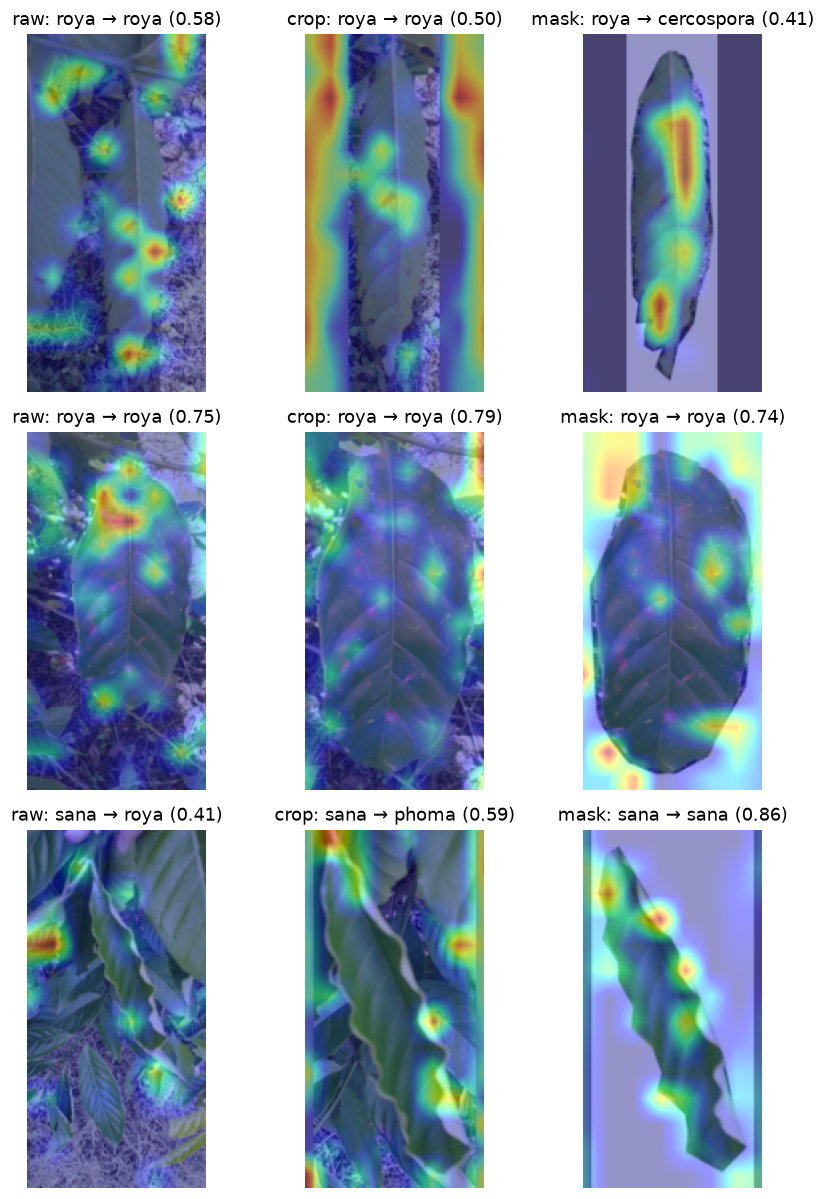

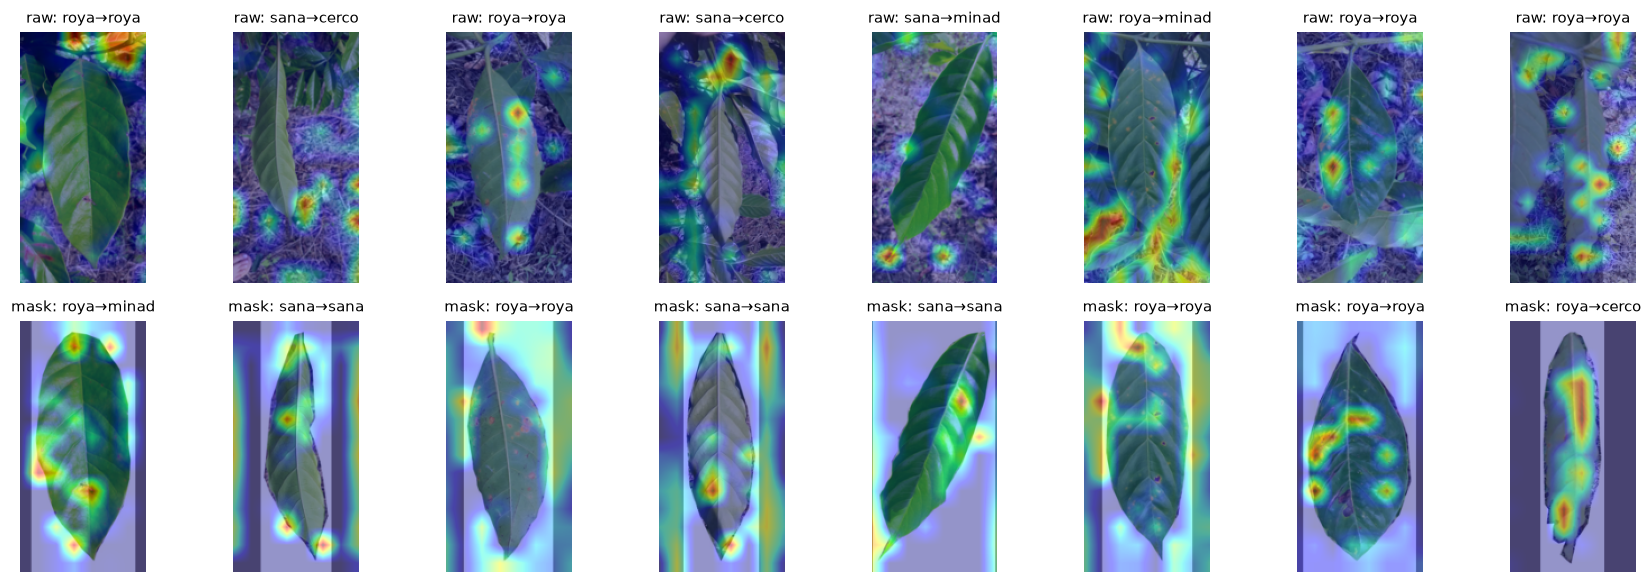

In [12]:
# (b) RoCoLe: misma hoja en raw / crop / mask con el mejor modelo (roya y sana)
gc = GradCAM(*models[BEST])
sel = list(roc[(roc.rocole_class.isin(["rust_level_2", "rust_level_3"]))].sample(2, random_state=3).index) + \
      list(roc[roc.rocole_class == "healthy"].sample(1, random_state=3).index)
fig, axes = plt.subplots(len(sel), 3, figsize=(8.4, 11))
for i, idx in enumerate(sel):
    for j, v in enumerate(C.ROCOLE_VERSIONS):
        x = caches[f"rocole_{v}"][idx]; cam, t, p = gc(tf(x))
        overlay(axes[i, j], x, cam, f"{v}: {roc.clase[idx]} → {C.CLASSES[t]} ({p:.2f})", crop="v")
plt.tight_layout(); plt.savefig(C.FIG / "03_gradcam_rocole.png"); plt.show()

# figura adicional: muchas hojas de RoCoLe raw vs mask (para cuantificar visualmente)
rng = np.random.default_rng(0)
many = rng.choice(ind, 8, replace=False)
fig, axes = plt.subplots(2, 8, figsize=(16, 5.4))
for j, idx in enumerate(many):
    for i, v in enumerate(["raw", "mask"]):
        x = caches[f"rocole_{v}"][idx]; cam, t, p = gc(tf(x))
        overlay(axes[i, j], x, cam, f"{v}: {roc.clase[idx][:4]}→{C.CLASSES[t][:5]}", crop="v", fs=10)
plt.tight_layout(); plt.savefig(C.FIG / "03_gradcam_rocole_muestra.png"); plt.show()

## 5. Fotos propias (opcional)
Si el equipo sube fotos de hojas de café a `MyDrive/ProyectoCafe/fotos_propias/` (subcarpetas con el nombre de la clase real,
p. ej. `sana/`, `roya/`, o sin subcarpeta si no se conoce), esta celda las clasifica con el mejor modelo.

In [13]:
from PIL import Image, ImageOps
from src.data import letterbox
fp = DRIVE / "fotos_propias"
files = sorted([p for p in fp.rglob("*") if p.suffix.lower() in (".jpg", ".jpeg", ".png")]) if fp.exists() else []
if not files:
    print("No hay fotos propias en", fp)
else:
    xs = torch.stack([torch.from_numpy(np.asarray(letterbox(ImageOps.exif_transpose(Image.open(f))))).permute(2, 0, 1) for f in files])
    pr = predict_proba(models[BEST][0], xs)
    n = len(files); cols = min(5, n); rws = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rws, cols, figsize=(3.2 * cols, 3.4 * rws), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, f, x, p in zip(axes.ravel(), files, xs, pr):
        real = f.parent.name if f.parent != fp else "?"
        cam, t, conf = gc(tf(x)); overlay(ax, x, cam, f"real: {real} → {C.CLASSES[p.argmax()]} ({p.max():.2f})")
    plt.tight_layout(); plt.savefig(C.FIG / "03_fotos_propias.png"); plt.show()

No hay fotos propias en C:\Users\LENOVO\Documents\UNIVERSIDAD\Deeplearning\Proyecto final\fotos_propias


In [14]:
# ===== Guardar resumen de métricas y empaquetar resultados =====
out = {"best_model": BEST, "val_f1": {r: summ[r]["best_val_f1"] for r in summ},
       "test": {r: {k: M[r][k] for k in ("accuracy", "f1_macro", "precision_macro", "recall_macro", "per_class", "confusion")} for r in M},
       "externo": ext_df.to_dict("records"), "ood": ood_df.to_dict("records"),
       "rocole_por_nivel": lvl.reset_index().to_dict("records"), "errores_multiestres": multi.reset_index().to_dict("records"),
       "n": {"test": int(len(y_test)), "rocole_in": int(len(ind)), "rocole_ood": int(len(ood))}}
json.dump(out, open(C.RUNS / "metrics.json", "w"), indent=2, default=float)
zp = DRIVE / "resultados.zip"
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
    for p in list(C.RUNS.rglob("*")) + list(C.FIG.rglob("*.png")):
        if p.is_file() and p.suffix != ".pt":
            z.write(p, p.relative_to(DRIVE))
print("Guardado", zp, f"{zp.stat().st_size / 1e6:.1f} MB")

Guardado C:\Users\LENOVO\Documents\UNIVERSIDAD\Deeplearning\Proyecto final\resultados.zip 22.4 MB


## 6. Discusión de resultados

**Test interno.** Los modelos preentrenados alcanzan 87–88 % de accuracy y superan a la CNN desde cero en 3,4–5,5 puntos de F1-macro. ViT-Tiny fue seleccionado por tener el mayor F1 de validación (0,935); en test EfficientNet-B0 queda 1–2 puntos arriba, una diferencia de 3–5 imágenes de 253 que no consideramos significativa. Distinguir sana de enferma es trivial en este dominio (AUROC 1,0, recall de sanas 100 %): todos los errores ocurren entre enfermedades. Cercospora, la clase minoritaria (22 imágenes de test), es la más difícil (F1 0,53) y se confunde con minador y roya. En hojas con un solo estrés la accuracy es 92 %, pero cae a 66 % en hojas con varios estreses simultáneos, donde la etiqueta «predominante» es ambigua. El resultado es inferior al 95,2 % de Esgario et al. (2020), que usaron ResNet-50 (≈ 6× más parámetros), otra partición y mayor resolución efectiva de la hoja (con nuestro letterbox la hoja ocupa la mitad del lienzo).

**Generalización.** La generalización se degrada fuertemente: con fotos de campo (raw) la accuracy del modelo seleccionado cae de 87,4 % a 31,3 % porque el 96 % de las hojas sanas se predice como enferma. Recortar la hoja apenas ayuda (34,7 %), pero reemplazar el fondo por blanco (mask) recupera 69,0 % de accuracy y una AUROC sana/enferma de 0,926 (recall sana 81 %, enferma 91 %). El patrón se repite en los tres modelos (AUROC raw 0,57–0,75 → mask 0,90–0,93), lo que indica que la mayor parte de la caída se debe al fondo y la condición de captura; la brecha restante se atribuye a la variedad robusta, la iluminación natural y la cámara. Grad-CAM lo confirma (Figura 2): en raw la activación se reparte entre la hoja y el fondo, y con mask se concentra en la lámina. En BRACOL, la CNN base localiza las lesiones con más precisión que el ViT, cuyos mapas activan a menudo el fondo: una métrica alta no garantiza que el modelo mire la evidencia correcta.

**Severidad:** con mask, la roya de nivel 1 se detecta en el 84 % de los casos y los niveles 2–4 en ≥ 99 % (falsos positivos en sanas: 19 %). **Clase nunca vista:** la arañita roja se asigna a roya (55 %) o minador (22 %) con la misma confianza que las clases conocidas (0,54 vs. 0,51; AUROC de detección por confianza máxima = 0,45, equivalente al azar). **Ablación:** sin aumento de datos el F1 en test casi no cambia (85,1 % vs. 86,4 %), pero la AUROC en RoCoLe se desploma (mask 0,59 vs. 0,90; raw 0,43 vs. 0,59): el aumento no mejora el test interno, pero decide la generalización.

**Conclusión.** Se cumplieron los tres objetivos. (1) El pipeline es reproducible y sin fuga (partición verificada por huella, aumento solo en entrenamiento, test usado una vez, RoCoLe solo para evaluar). (2) El preentrenamiento es decisivo: ViT-Tiny y EfficientNet-B0 logran 87–88 % de accuracy en test frente a 84 % de la CNN desde cero. (3) La generalización a campo se degrada drásticamente (87 % → 31 %), y el experimento raw/crop/mask junto con Grad-CAM muestran que la causa principal es el fondo: el modelo aprendió atajos ligados a la condición de captura de laboratorio. La conclusión central es que un buen resultado en el test interno no implica un modelo útil en campo. **Limitaciones:** una sola partición y semilla (sin intervalos de confianza), etiqueta predominante ambigua en hojas con varios estreses, RoCoLe solo evalúa sana y roya, entrenamiento en CPU con pocas épocas y sin búsqueda de hiperparámetros, y el modelo no detecta clases desconocidas. **Mejoras:** segmentar la hoja antes de clasificar, entrenar con imágenes de campo o aumentos de fondo, formulación multietiqueta, mayor resolución y rechazo de entradas fuera de distribución.